# Chapter 8 — Bundle adjustment

Companion notebook to **Chapter 8**. The block structure of the normal equations, the Schur complement, the gauge,
covariance recovery, and a sliding-window bundle adjustment inside the stereo VO of Chapter 7.

The solver is `vslam.ba`: observations are stored as flat arrays (camera index, point index, measurement), and every
quantity is computed for all observations at once.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
from vslam import ba, lie, metrics, robust, sim, vo
from ch08_ba import synthetic_ba, SIGMA

np.set_printoptions(precision=4, suppress=True)
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. The arrowhead (Proposition 8.2)

Eight cameras moving past 60 points, each camera seeing 40 % of them. $U$ and $V$ are block diagonal; $W$ has a block
wherever a camera sees a point.

unknowns: 222 = 42 (7 free cameras) + 180 (60 points)
non-zero entries of H: 13.8%
off-diagonal blocks of U non-zero? False
off-diagonal blocks of V non-zero? False


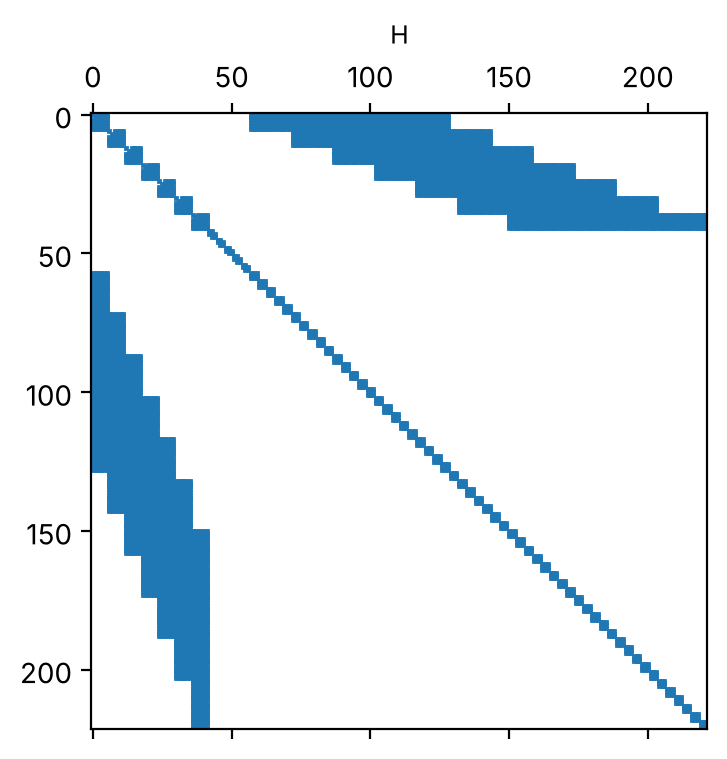

In [2]:
pb, cams, pts = synthetic_ba(n_cams=8, n_pts=60, visible=0.4)
H, g = ba.dense_system(pb)
print("unknowns:", H.shape[0], "=", 6 * 7, "(7 free cameras) +", 3 * 60, "(60 points)")
print(f"non-zero entries of H: {np.mean(np.abs(H) > 1e-12):.1%}")
nc = 42
U, V, W = H[:nc, :nc], H[nc:, nc:], H[:nc, nc:]
print("off-diagonal blocks of U non-zero?", np.abs(U - np.kron(np.eye(7), np.ones((6, 6))) * U).max() > 0)
print("off-diagonal blocks of V non-zero?", np.abs(V - np.kron(np.eye(60), np.ones((3, 3))) * V).max() > 0)
plt.figure(figsize=(4, 4)); plt.spy(np.abs(H) > 1e-12, markersize=0.8); plt.title("H", fontsize=9);

## 2. The Schur complement gives the same step (Theorem 8.3)

In [3]:
r, A, B, _ = pb.residuals_jacobians()
U, V, Wk, g_c, g_p = pb.normal_equations(r, A, B, np.ones(len(r)))
S, b, Vinv, pos = pb.schur(U, V, Wk, g_c, g_p)
dc, dp = pb.back_substitute(np.linalg.solve(S, b), pos, Vinv, Wk, g_p)
delta = np.linalg.solve(H, -g)
print("reduced system size:", S.shape, " full system size:", H.shape)
print("max |dense - Schur| on cameras:", np.abs(delta[:nc] - dc[1:].ravel()).max())
print("max |dense - Schur| on points: ", np.abs(delta[nc:] - dp.ravel()).max())

reduced system size: (42, 42)  full system size: (222, 222)
max |dense - Schur| on cameras: 5.6114141111507365e-12
max |dense - Schur| on points:  4.6118664442929e-12


## 3. The gauge (Section 8.4)

Without any fixed camera, the cost does not change under a global rigid motion (stereo) or a global similarity
(monocular), and $H$ has that many zero eigenvalues.

In [4]:
for stereo in [True, False]:
    for fixed in [set(), {0}, {0, 1}]:
        p_, _, _ = synthetic_ba(n_cams=6, n_pts=80, stereo=stereo, perturb=False, noise=0.0)
        p_.fixed = fixed
        ev = np.linalg.eigvalsh(ba.dense_system(p_)[0])
        print(f"{'stereo' if stereo else 'mono  '}, fixed cameras {str(sorted(fixed)):7}: "
              f"{np.sum(ev < 1e-8 * ev[-1])} zero eigenvalues")

stereo, fixed cameras []     : 6 zero eigenvalues
stereo, fixed cameras [0]    : 0 zero eigenvalues
stereo, fixed cameras [0, 1] : 0 zero eigenvalues
mono  , fixed cameras []     : 7 zero eigenvalues
mono  , fixed cameras [0]    : 1 zero eigenvalues
mono  , fixed cameras [0, 1] : 0 zero eigenvalues


Fixing one camera removes six dimensions. With monocular observations one remains, the scale; fixing a second
camera removes it too (and over-constrains the problem slightly: it also fixes the distance between the two cameras).

## 4. Solving, and checking the result (Section 8.3, Proposition 4.12)

In [5]:
pb, cams, pts = synthetic_ba(n_cams=8, n_pts=300, visible=0.5, seed=3)
res = ba.solve(pb, max_iters=30)
m = pb.z.size
n = 6 * 7 + 3 * len(pts)
print("cost per iteration:", np.round(res.costs, 1))
print(f"final 2F = {2 * res.costs[-1]:.0f},  m - n = {m - n}")
err = [np.linalg.norm(Te[:3, 3] - Tt[:3, 3]) for Te, Tt in zip(res.cams, cams)]
print("camera position errors [cm]:", np.round(100 * np.array(err), 2))

cost per iteration: [163497.6   1398.1   1365.1   1364.8   1364.8   1364.8   1364.8]
final 2F = 2730,  m - n = 2658
camera position errors [cm]: [0.   0.88 1.97 2.97 4.23 4.72 5.94 6.22]


## 5. Covariance from the reduced system (Proposition 8.5)

The marginal covariance of a camera is a diagonal block of $S^{-1}$: the reduced system *is* the information matrix of
the cameras with the points marginalised (Lemma 1.8). Check against 60 noise draws.

In [6]:
est = []
for s in range(60):
    p_, c_, _ = synthetic_ba(n_cams=6, n_pts=80, visible=0.6, seed=100 + s)
    est.append(ba.solve(p_, max_iters=20).cams[5][:3, 3] - c_[5][:3, 3])
p_, c_, _ = synthetic_ba(n_cams=6, n_pts=80, visible=0.6, seed=100)
ba.solve(p_, max_iters=20)
R = p_.cams[5][:3, :3]
pred = np.sqrt(np.diag(R @ ba.camera_covariance(p_)[5][:3, :3] @ R.T))
print("last camera, position std [cm]")
print("  predicted  :", np.round(100 * pred, 2))
print("  Monte Carlo:", np.round(100 * np.array(est).std(axis=0), 2))

last camera, position std [cm]
  predicted  : [5.   2.35 1.02]
  Monte Carlo: [3.97 2.09 1.03]


## 6. Local bundle adjustment in the VO (Section 8.6)

The VO of Chapter 7 kept its keyframe map fixed. `StereoVOBA` keeps map points alive while their tracks continue and,
at every keyframe, optimises the last six keyframes and the points they see, holding the oldest one fixed.

     keyframes (Ch. 7): 50 keyframes, final error 40.1 cm


  keyframes + local BA: 125 keyframes, final error 5.3 cm


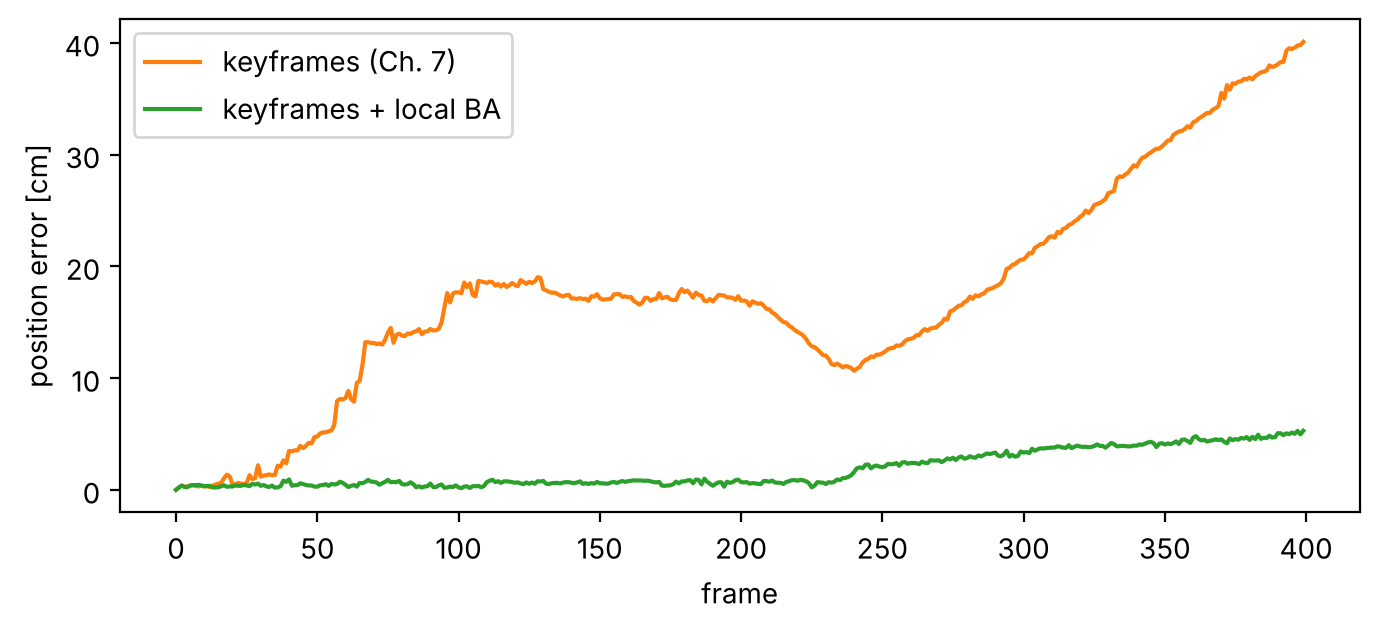

In [7]:
world = sim.garden(np.random.default_rng(0)); S = sim.GardenSim()
frames = S.run(world, sim.boustrophedon()[:400], sim.camera_mount(), np.random.default_rng(1))
gt = np.array([f.T_wc[:3, 3] for f in frames])
fig, ax = plt.subplots(figsize=(8, 3.2))
for name, V, col in [("keyframes (Ch. 7)", vo.StereoVO(S.stereo, SIGMA, rng=np.random.default_rng(0)), "tab:orange"),
                     ("keyframes + local BA", vo.StereoVOBA(S.stereo, SIGMA, rng=np.random.default_rng(0)), "tab:green")]:
    est = V.run(frames, frames[0].T_wc)
    e = np.array([T[:3, 3] for T in est])
    ax.plot(100 * np.linalg.norm(e - gt, axis=1), color=col, label=name)
    print(f"{name:>22}: {len(V.stats.keyframes)} keyframes, final error {100 * np.linalg.norm(e[-1] - gt[-1]):.1f} cm")
ax.set_xlabel("frame"); ax.set_ylabel("position error [cm]"); ax.legend();

## 7. Try it yourself

* Set `window=2` in `StereoVOBA`: only the newest keyframe moves. How much of the gain remains?
* Turn the kernel off in `StereoVOBA._local_ba` (`kernel=None`). The simulator has 10 % wrong measurements on grass:
  what happens?
* In section 4, use monocular observations (`stereo=False`) and fix only camera 0. LM still converges: why, and what
  does the scale of the solution depend on?